# CA2 - Data Preparation and Exploratory Data Analysis

**Project:** Predicting Orbital Decay of Low Earth Orbit Objects to Support Satellite Operators' Disposal Planning

**Student:** Oleksii Taranov (sba26106)

**Module:** Strategic Thinking

**GitHub:** https://github.com/sba26106-bit/strategic-think-ca1

## 1. Business understanding

### Background
Low Earth Orbit (LEO) is becoming increasingly congested. About 40,000 objects are tracked around Earth, but only about 11,000 are operational satellites; the rest are defunct satellites, used rocket bodies and fragments (European Space Agency, 2025). The US Federal Communications Commission now requires spacecraft planned for uncontrolled re-entry to leave orbit within **five years** after the mission ends, replacing the earlier 25-year benchmark (Federal Communications Commission, 2024). ESA applies the same limit to its own missions (European Space Agency, 2023).

### Business problem
When a mission ends, the operator must decide whether the satellite will re-enter within five years on its own, or whether it needs a disposal manoeuvre to lower its orbit. The manoeuvre uses fuel that could otherwise extend the mission. A wrong estimate either wastes fuel or leaves an object that breaks the rule. A licensing authority must then check that decision.

Lifetime is currently estimated with physics-based tools such as ESA's DRAMA/OSCAR (Braun et al., 2020). These tools need the object's mass, cross-section and a fitted drag value, and their results remain uncertain: ESA applies a margin of ±20% to its own re-entry predictions (European Space Agency, 2018). More than 60 years of public tracking records contain many complete examples of orbital decay, which can support a faster, data-driven estimate.

### Project aim and data mining goal
**Aim:** to develop and evaluate a model that estimates how long an uncontrolled LEO object will remain in orbit, based on its current orbit and solar conditions.

**Data mining goal:** predict the **remaining orbital lifetime** of an object from one orbit record, and turn it into a **probability of re-entry within five years**.

**Hypothesis H1:** a model that includes solar-activity features known at the time of prediction (F10.7 solar flux and Ap index) predicts lifetime more accurately on unseen objects than the same model with orbital features only. **H0:** adding these features does not improve accuracy.

### Success criteria
- **Business:** the model identifies objects that will (or will not) re-enter within five years better than a simple rule based on altitude alone.
- **Analytical:** the model reaches a higher concordance index (C-index) on unseen objects than a baseline Cox model that uses perigee altitude only.

### Scope
- **Included:** tracked objects whose whole orbit lies below 2,000 km; rocket bodies, debris and satellites whose mission has ended; natural, uncontrolled decay from 1959 to 2026.
- **Excluded:** satellites that still manoeuvre, controlled re-entries, objects above LEO, re-entry location and ground risk.

### What this notebook covers (CA2)
This notebook covers the CRISP-DM phases **data understanding** and **data preparation**, plus exploratory analysis. It delivers project objectives 1 and 2:
1. build one cleaned and labelled dataset from the orbit history, re-entry dates and daily space weather;
2. analyse how remaining lifetime changes with altitude, object type and solar activity.

Modelling, evaluation, the formal test of H1 and the dashboard follow in Semester 2.

## 2. Data understanding

In [1]:
# Import libraries

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
from scipy import stats

In [2]:
# Folders and settings used in the whole notebook

DATA = Path("data")                      # the data folder path
RAW = DATA / "raw"                       # original downloads - this notebook never changes them
TLE_DIR = RAW / "tle_history"            # raw orbit history: 68 yearly Parquet files
OUT = DATA / "processed" / "ca2"         # everything this notebook writes goes here
STAGE = OUT / "stage1"                   # weekly LEO records after the first preparation pass
PREP = OUT / "prepared"                  # final prepared records for modelling
FIG = Path("figures")                    # saved charts for the report

SATCAT_FILE = RAW / "celestrak_satcat_2026-10-04.csv"
SPACEWEATHER_FILE = RAW / "spaceweather_2026-10-04.csv"
CATALOG_DATE = pd.Timestamp("2026-10-04")   # SATCAT snapshot date = end of observation (censoring date)

R_EARTH = 6378.137        # Earth radius (km)
MU = 398600.4418          # Earth's gravitational parameter (km^3/s^2)
LEO_MAX_KM = 2000         # LEO upper limit: apogee must be at or below this height
MIN_PERIGEE_KM = 80       # records with a lower perigee are bad orbit fits
SEED = 42                 # fixed random seed, so samples and splits can be reproduced

# Creating folders for prepared data
for folder in [STAGE, PREP]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

raw_files = sorted(TLE_DIR.glob("tle_*.parquet"))
print(f"Data folder: {DATA.resolve()}")
print(f"Raw orbit history files: {len(raw_files)}")
print(f"SATCAT found: {SATCAT_FILE.exists()} | Space weather found: {SPACEWEATHER_FILE.exists()}")

Data folder: C:\Users\oleks\Documents\CCT College Dublin\Strategical thinking\CA2\Submission\data
Raw orbit history files: 68
SATCAT found: True | Space weather found: True


### 2.1 Sources

The project uses **one main dataset** - the orbit history - and **two small lookup tables** that are joined to it. The lookup tables add the label (re-entry date) and the solar-activity features; they are checked for completeness but are not cleaned and explored as separate datasets.

The amounts are the **expected (approximate)** sizes, taken from the source descriptions and the download step. The exact numbers of rows and objects are calculated with Python in section 2.2.

| Role | Source | File | Content | Expected amount | Permission |
|---|---|---|---|---|---|
| Main dataset | Space-Track.org orbit history, via a public Parquet copy (Simon, 2026) | data/raw/tle_history/ | Orbital elements, drag term and decay rate for every tracked object, 1959-2026 | About 239.5 million records in 68 yearly files (about 12.5 GB) | Basic data redistributable with citation (Space-Track.org, 2026); copy under CC BY 4.0 licence |
| Lookup: labels | CelesTrak SATCAT (CelesTrak, 2026a) | data/raw/celestrak_satcat_2026-10-04.csv | Object type, operational status, launch and re-entry dates | About 70,000 catalogued objects since 1957 | Free public data; the CelesTrak usage policy is followed; CelesTrak and the original providers are cited |
| Lookup: solar activity | CelesTrak space weather (CelesTrak, 2026b) | data/raw/spaceweather_2026-10-04.csv | Daily F10.7 solar flux, Kp/Ap indices, sunspot number | About 25,000 daily rows since October 1957 | Free public data; CelesTrak and the original providers are cited |

Other sources were considered (ESA DISCOSweb for mass and size, GCAT, the NOAA solar-cycle forecast). They are not used, to keep the scope manageable; mass and size are noted as a possible future improvement.

### 2.2 Exact size and structure of the data
Each source is checked in the same four steps:
1. **Size and completeness** - exact number of rows and objects, duplicates and missing values;
2. **Structure** - column types and the first rows;
3. **Fields and completeness explained** - what the fields used in this project mean, and what the checks show;
4. **Content** - a first look at what the data contains.

#### 2.2.1 Main dataset: Space-Track.org orbit history
The number of records and the missing values are read from each file's metadata, so the 12.5 GB of data does not need to be loaded. Distinct objects and duplicate records are counted from the `norad_id` and `epoch` columns only.

In [3]:
# Size and completeness of the raw orbit history.
# The 68 yearly files are read one at a time, and only the columns that are needed,
# so the whole 12.5 GB never has to be held in memory.

raw_size = []      # one row of results per yearly file
all_ids = set()    # NORAD numbers of all objects; a set keeps each number only once
raw_missing = {}   # number of missing values per column, summed over all files

for f in raw_files:
    pf = pq.ParquetFile(f)   # opens the file and reads only its metadata (the summary at the end of the file)

    # Load only the object number and the time of each record
    d = pd.read_parquet(f, columns=["norad_id", "epoch"])

    # Add this file's objects to the overall set.
    # An object usually appears in several years, so counting per file and adding the counts would count it many times.
    all_ids.update(d["norad_id"].unique())

    raw_size.append({
        "year": int(f.stem[-4:]),                          # year from the file name, e.g. "tle_1990" -> 1990
        "records": pf.metadata.num_rows,                   # number of records, taken from the metadata
        "objects": d["norad_id"].nunique(),                # distinct objects in this year
        "duplicate_records": int(d.duplicated().sum()),    # records repeated for the same object at the same epoch
        "size_MB": round(f.stat().st_size / 1e6, 1),       # file size on disk in megabytes
    })

    # Missing values per column, taken from statistics stored in the file (no data loaded).
    # A Parquet file is split into blocks called "row groups". Each row group stores,
    # for every column, how many of its values are missing (null_count).
    for i in range(pf.metadata.num_row_groups):
        rg = pf.metadata.row_group(i)                      # metadata of one row group
        for j in range(rg.num_columns):
            col = rg.column(j)                             # metadata of one column in this row group
            # Some files may not store statistics; in that case 0 is counted
            nulls = col.statistics.null_count if col.statistics is not None else 0
            # Add to the running total for this column name (start from 0 the first time)
            raw_missing[col.path_in_schema] = raw_missing.get(col.path_in_schema, 0) + nulls

# Turn the list of results into a table with one row per year
raw_size = pd.DataFrame(raw_size).set_index("year")

print(f"Records: {raw_size['records'].sum():,} | distinct objects: {len(all_ids):,} | "
      f"files: {len(raw_files)} | size: {raw_size['size_MB'].sum() / 1000:.1f} GB")
print(f"Duplicate records (same object and epoch): {raw_size['duplicate_records'].sum():,} "
      f"({raw_size['duplicate_records'].sum() / raw_size['records'].sum():.1%} of all records)")
print(f"Missing values per column: {raw_missing}")

Records: 251,312,863 | distinct objects: 68,197 | files: 68 | size: 12.5 GB
Duplicate records (same object and epoch): 17,570,440 (7.0% of all records)
Missing values per column: {'norad_id': 0, 'epoch': 0, 'inclination': 0, 'raan': 0, 'eccentricity': 0, 'arg_perigee': 0, 'mean_anomaly': 0, 'mean_motion': 0, 'mean_motion_dot': 0, 'bstar': 0, 'intl_designator': 0, 'altitude_km': 0}


In [4]:
# Structure: column types and the first rows of the latest file
example = next(pq.ParquetFile(raw_files[-1]).iter_batches(batch_size=5)).to_pandas()
print(example.dtypes.to_string())
example

norad_id                         int32
epoch              datetime64[us, UTC]
inclination                    float32
raan                           float32
eccentricity                   float32
arg_perigee                    float32
mean_anomaly                   float32
mean_motion                    float64
mean_motion_dot                float64
bstar                          float64
intl_designator                    str
altitude_km                    float32


,norad_id,epoch,inclination,raan,eccentricity,arg_perigee,mean_anomaly,mean_motion,mean_motion_dot,bstar,intl_designator,altitude_km
0,5,2026-01-01 08:22:35.059296+00:00,34.243698,109.205902,0.183993,106.250504,274.750702,10.859406,8.300000e-07,0.000125,58002B,657.969971
1,5,2026-01-02 15:16:44.336928+00:00,34.243999,105.231400,0.183991,112.055000,268.509003,10.859409,9.400000e-07,0.000138,58002B,657.989990
2,5,2026-01-03 08:56:13.002144+00:00,34.244099,102.960403,0.183989,115.371803,264.836487,10.859411,9.500000e-07,0.000137,58002B,658.000000
3,5,2026-01-03 15:33:30.820032+00:00,34.244099,102.108597,0.183989,116.615799,263.439087,10.859409,6.700000e-07,0.000102,58002B,658.000000
4,5,2026-01-04 07:00:31.442976+00:00,34.244099,100.121399,0.183987,119.518303,260.136292,10.859409,5.200000e-07,0.000082,58002B,658.020020


**Fields used in this project.** Each record is one orbit estimate (a "two-line element set") for one object at one time.
- `norad_id` - the object's catalogue number (NORAD number); the key for joining the SATCAT,
- `epoch` - the date and time of the orbit estimate (UTC),
- `mean_motion` - revolutions per day; it gives the size of the orbit (semi-major axis),
- `eccentricity` - how elongated the orbit is; with the semi-major axis it gives perigee and apogee height,
- `inclination` - the tilt of the orbit,
- `bstar` - a fitted drag term, and `mean_motion_dot` - how fast the orbit is shrinking.

The other columns (`raan`, `arg_perigee`, `mean_anomaly`, `intl_designator`, `altitude_km`) are not used.

**Completeness.**
- **Size:** the exact count of 251,312,863 records is higher than the expected 239.5 million in the source description, so the exact numbers are used from here on. The records cover 68,197 distinct objects.
- **Missing values:** none in any column.
- **Duplicates:** 17,570,440 records (7.0%) repeat an earlier record of the same object at **exactly the same epoch**, down to the microsecond. Only the object number and the epoch are compared, so these columns do not show whether the other values of a duplicate are identical. Records of the same object a few hours apart are *not* duplicates; they are normal repeated orbit estimates. No separate cleaning step is needed: preparation keeps only the first record of each object in each week (step 3), which also removes the duplicates.

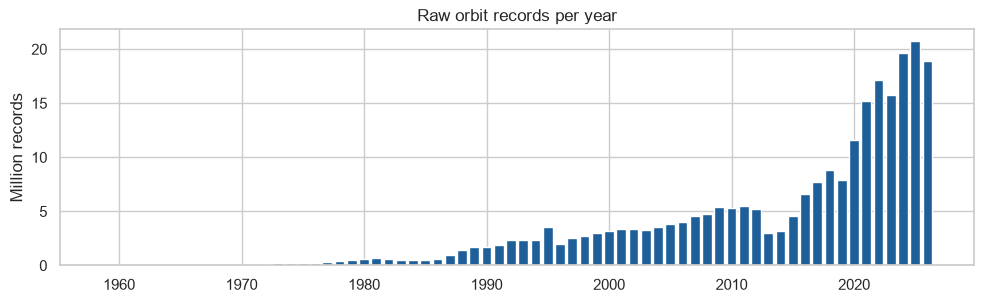

,records,objects,duplicate_records,size_MB
year,,,,
2022,17139087,27607,3070192,861.1
2023,15740029,28194,2587550,789.6
2024,19654504,29542,3670329,979.0
2025,20779646,31711,3134972,1035.6
2026,18937812,32842,0,730.9


In [5]:
# Content: records, objects and duplicates per year
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(raw_size.index, raw_size["records"] / 1e6, color="#1f5f99")
ax.set(title="Raw orbit records per year", xlabel="", ylabel="Million records")
fig.tight_layout(); fig.savefig(FIG / "fig_raw_records.png", dpi=150); plt.show()

# The last five years (the most recent and largest files)
raw_size.tail()

Each row of the table is one yearly file: `records` - orbit records in the file, `objects` - different objects with at least one record that year, `duplicate_records` - exact duplicates (see above), `size_MB` - file size on disk.

- The number of records grew strongly after about 2015. Recent years have 15.7-20.8 million records for 28,000-33,000 objects: about 560-670 records per object per year, or 1.5-1.8 orbit estimates per object per day. One record per week is enough for this project, so the weekly rule reduces the data size a lot without losing information.
- In 2022-2025, about 15-19% of records are exact duplicates (for example, 3,070,192 of 17,139,087 in 2022).
- The 2026 file covers only part of the year (up to the download date) and has no duplicates at all. The reason is not documented. This does not affect the results, because step 3 removes duplicates in every year.
- The number of objects keeps growing every year, which matches the growth of large satellite constellations.

#### 2.2.2 Lookup table: CelesTrak SATCAT (object types and re-entry dates)

In [6]:
# Size and completeness of the SATCAT
satcat = pd.read_csv(SATCAT_FILE, parse_dates=["LAUNCH_DATE", "DECAY_DATE"])

print(f"Rows (objects): {len(satcat):,} | columns: {satcat.shape[1]}")
print(f"Duplicated NORAD numbers: {satcat['NORAD_CAT_ID'].duplicated().sum()}")
print(f"Missing values in the fields used: "
      f"{satcat[['NORAD_CAT_ID', 'OBJECT_NAME', 'OBJECT_TYPE', 'OPS_STATUS_CODE', 'DECAY_DATE']].isna().sum().to_dict()}")

Rows (objects): 70,882 | columns: 17
Duplicated NORAD numbers: 0
Missing values in the fields used: {'NORAD_CAT_ID': 0, 'OBJECT_NAME': 0, 'OBJECT_TYPE': 0, 'OPS_STATUS_CODE': 16524, 'DECAY_DATE': 35229}


In [7]:
# Structure: column types and the first rows
print(satcat.dtypes.to_string())
satcat.head()

OBJECT_NAME                    str
OBJECT_ID                      str
NORAD_CAT_ID                 int64
OBJECT_TYPE                    str
OPS_STATUS_CODE                str
OWNER                          str
LAUNCH_DATE         datetime64[us]
LAUNCH_SITE                    str
DECAY_DATE          datetime64[us]
PERIOD                     float64
INCLINATION                float64
APOGEE                     float64
PERIGEE                    float64
RCS                        float64
DATA_STATUS_CODE               str
ORBIT_CENTER                   str
ORBIT_TYPE                     str


,OBJECT_NAME,OBJECT_ID,NORAD_CAT_ID,OBJECT_TYPE,OPS_STATUS_CODE,OWNER,LAUNCH_DATE,LAUNCH_SITE,DECAY_DATE,PERIOD,INCLINATION,APOGEE,PERIGEE,RCS,DATA_STATUS_CODE,ORBIT_CENTER,ORBIT_TYPE
0,SL-1 R/B,1957-001A,1,R/B,D,CIS,1957-10-04,TYMSC,1957-12-01,96.19,65.10,938.0,214.0,20.420,NaN,EA,IMP
1,SPUTNIK 1,1957-001B,2,PAY,D,CIS,1957-10-04,TYMSC,1958-01-03,96.10,65.00,1080.0,64.0,NaN,NaN,EA,IMP
2,SPUTNIK 2,1957-002A,3,PAY,D,CIS,1957-11-03,TYMSC,1958-04-14,103.74,65.33,1659.0,211.0,0.080,NaN,EA,IMP
3,EXPLORER 1,1958-001A,4,PAY,D,US,1958-02-01,AFETR,1970-03-31,88.48,33.15,215.0,183.0,NaN,NaN,EA,IMP
4,VANGUARD 1,1958-002B,5,PAY,NaN,US,1958-03-17,AFETR,NaT,132.59,34.26,3819.0,651.0,0.122,NaN,EA,ORB


**Fields used in this project.**
- `NORAD_CAT_ID` - the catalogue number; the key for joining the orbit history,
- `OBJECT_TYPE` - `PAY` = payload (satellite), `R/B` = rocket body, `DEB` = debris, `UNK` = unknown type,
- `OPS_STATUS_CODE` - operational status (for example `+` = operational, `D` = decayed); used to remove satellites that still work (step 8),
- `DECAY_DATE` - the re-entry date; gives the label (remaining lifetime) and whether the object has re-entered,
- `OBJECT_NAME` - used only to check the share of Starlink satellites (section 4.7).

The other columns (owner, launch site, orbit values at the catalogue date, `RCS` and others) are not used.

**Completeness.**
- **Size:** 70,882 objects, as expected (about 70,000).
- **Duplicates:** none. Each object appears once, so the NORAD number is a safe join key (step 6).
- **Missing values:** `NORAD_CAT_ID`, `OBJECT_NAME` and `OBJECT_TYPE` are complete. `DECAY_DATE` and `OPS_STATUS_CODE` have missing values, but these have a meaning; they are explained with the tables below.

In [8]:
# Content: object types and re-entry status
satcat["reentry_status"] = np.where(satcat["DECAY_DATE"].notna(), "re-entered", "in orbit")
pd.crosstab(satcat["OBJECT_TYPE"], satcat["reentry_status"], margins=True)

reentry_status,in orbit,re-entered,All
OBJECT_TYPE,,,
DEB,12533,23375,35908
PAY,20209,7691,27900
R/B,2431,4477,6908
UNK,56,110,166
All,35229,35653,70882


- **`DECAY_DATE` is missing for 35,229 objects – exactly the number still in orbit.** A missing re-entry date is therefore not an error: it means the object has not re-entered yet. These objects are **censored**: their lifetime is only known to be longer than the time observed, and survival analysis uses them in that form. About half of all objects have already re-entered, so the data contains many complete lifetimes.
- **166 objects (0.2%) have the type `UNK`.** This is effectively missing information recorded as a category. These objects stay in the prepared data but are left out of the analysis sample (section 3.3), because there are too few of them to analyse as a group.

In [9]:
# Content: how many objects of each type have no operational status
pd.crosstab(satcat["OBJECT_TYPE"], satcat["OPS_STATUS_CODE"].isna().rename("status missing"))

status missing,False,True
OBJECT_TYPE,,
DEB,23375,12533
PAY,26392,1508
R/B,4481,2427
UNK,110,56


**Missing operational status (`OPS_STATUS_CODE`, 16,524 objects) by object type.**
- **Debris, rocket bodies and unknown objects:** the status is missing only for objects still in orbit. The counts match the "in orbit" column of the previous table exactly for debris (12,533) and unknown objects (56), and almost exactly for rocket bodies (2,427 of 2,431). Re-entered objects have the status `D` (decayed). For pieces that can never be operational, a missing status is expected and is not a data problem.
- **Payloads:** 1,508 of 27,900 satellites (5.4%) have no status, so it is not known whether they still work. They are treated as not operational and stay in the data; step 8 removes only satellites marked as operational.
- **Risk and how it is handled:** some of these satellites may still be active. Their orbit raises are caught by the manoeuvre rule (step 9), which keeps only the records after an object's last manoeuvre. Active satellites without a detected raise would remain; this is noted as a limitation.

#### 2.2.3 Lookup table: CelesTrak space weather (daily solar activity)

In [10]:
# Size and completeness of the space-weather file
sw_all = pd.read_csv(SPACEWEATHER_FILE, parse_dates=["DATE"])

print(f"Rows (days): {len(sw_all):,} | columns: {sw_all.shape[1]} | "
      f"dates: {sw_all['DATE'].min().date()} to {sw_all['DATE'].max().date()}")
print(f"Duplicated dates: {sw_all['DATE'].duplicated().sum()}")
print("Row types:", sw_all["F10.7_DATA_TYPE"].value_counts().to_dict())

sw = sw_all[sw_all["F10.7_DATA_TYPE"].isin(["OBS", "INT"])].copy()     # observed values only, no forecasts
print(f"Observed rows kept: {len(sw):,} ({sw['DATE'].min().date()} to {sw['DATE'].max().date()})")
print(f"Missing values in the fields used (observed rows): "
      f"{sw[['DATE', 'F10.7_OBS', 'F10.7_OBS_LAST81', 'AP_AVG']].isna().sum().to_dict()}")

Rows (days): 25,429 | columns: 31 | dates: 1957-10-01 to 2041-10-01
Duplicated dates: 0
Row types: {'OBS': 25145, 'PRM': 179, 'INT': 60, 'PRD': 45}
Observed rows kept: 25,205 (1957-10-01 to 2026-10-03)
Missing values in the fields used (observed rows): {'DATE': 0, 'F10.7_OBS': 0, 'F10.7_OBS_LAST81': 0, 'AP_AVG': 0}


In [11]:
# Structure: column types and the first rows of the fields used
print(sw_all.columns.tolist())
sw_all[["DATE", "F10.7_DATA_TYPE", "F10.7_OBS", "F10.7_OBS_LAST81", "AP_AVG"]].head()

['DATE', 'BSRN', 'ND', 'KP1', 'KP2', 'KP3', 'KP4', 'KP5', 'KP6', 'KP7', 'KP8', 'KP_SUM', 'AP1', 'AP2', 'AP3', 'AP4', 'AP5', 'AP6', 'AP7', 'AP8', 'AP_AVG', 'CP', 'C9', 'ISN', 'F10.7_OBS', 'F10.7_ADJ', 'F10.7_DATA_TYPE', 'F10.7_OBS_CENTER81', 'F10.7_OBS_LAST81', 'F10.7_ADJ_CENTER81', 'F10.7_ADJ_LAST81']


,DATE,F10.7_DATA_TYPE,F10.7_OBS,F10.7_OBS_LAST81,AP_AVG
0,1957-10-01,OBS,269.3,230.9,21.0
1,1957-10-02,OBS,253.3,231.7,12.0
2,1957-10-03,OBS,266.3,232.7,19.0
3,1957-10-04,OBS,238.2,233.3,12.0
4,1957-10-05,OBS,246.2,233.9,10.0


**Fields used in this project.**
- `DATE` - the day; the key for joining the orbit history,
- `F10.7_DATA_TYPE` - `OBS` = observed, `INT` = interpolated, `PRD`/`PRM` = forecast,
- `F10.7_OBS` - daily solar radio flux at 10.7 cm (solar flux units, sfu), a standard measure of solar activity,
- `F10.7_OBS_LAST81` - average of F10.7 over the **last** 81 days (only past values, so no future information),
- `AP_AVG` - daily average of the Ap geomagnetic index; its 81-day trailing average is calculated in step 7.

The other columns (Kp and Ap per three hours, sunspot number, adjusted and centred averages) are not used. The centred 81-day averages (`..._CENTER81`) are avoided on purpose, because they include 40 days of future values.

**Completeness.**
- **Size:** 25,429 rows from October 1957 to 2041. The file runs to 2041 because it also contains forecast rows (`PRD`/`PRM`). These are removed; the 25,205 observed and interpolated rows are kept, as expected (about 25,000).
- **Duplicates:** none; each date appears once, so the date is a safe join key.
- **Missing values:** none in the fields used.

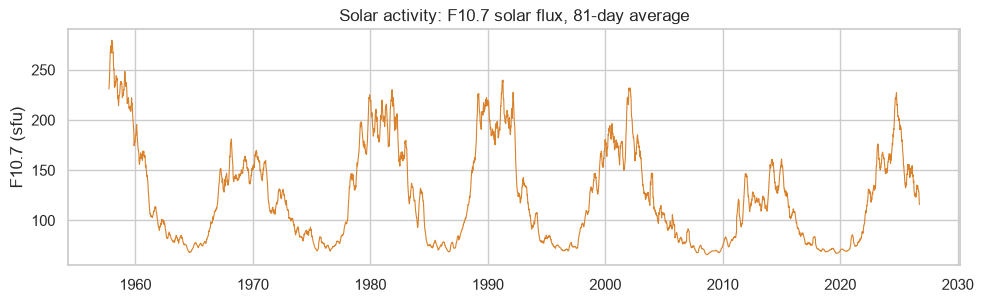

,F10.7_OBS,F10.7_OBS_LAST81,AP_AVG
count,25205.0,25205.0,25205.0
mean,123.0,123.2,12.8
std,52.4,47.8,14.7
min,53.5,65.8,0.0
25%,78.0,79.3,5.0
50%,108.3,111.8,8.0
75%,154.6,156.9,16.0
max,938.6,279.5,280.0


In [12]:
# Content: the solar cycle and summary statistics
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(sw["DATE"], sw["F10.7_OBS_LAST81"], lw=0.8, color="#d9822b")
ax.set(title="Solar activity: F10.7 solar flux, 81-day average", xlabel="", ylabel="F10.7 (sfu)")
fig.tight_layout(); fig.savefig(FIG / "fig_solar_cycle.png", dpi=150); plt.show()
sw[["F10.7_OBS", "F10.7_OBS_LAST81", "AP_AVG"]].describe().round(1)

- Solar activity rises and falls in cycles of about 11 years. A more active Sun heats and expands the upper atmosphere, which increases drag (Vallado and Finkleman, 2014).
- **Daily values contain short extreme spikes:** daily F10.7 reaches 938.6 sfu (solar flares) and Ap reaches 280 (geomagnetic storms), while the medians are 108.3 and 8. The 81-day average (maximum 279.5) smooths these spikes out, so it is the main solar feature; the daily values are kept as well.

## 3. Data preparation
All preparation starts from the raw files. The two lookup tables are joined to the orbit history (steps 6 and 7), so the result is **one combined table**. The orbit history is too large to load at once, so it is processed **one yearly file at a time** and, inside each file, in batches of one million records.